# APTOS Blindness Detection: EfficientNetB0

This notebook trains a frozen ImageNet-pretrained EfficientNetB0 on the existing balanced APTOS split. Images are loaded directly from the split folders without CLAHE, normalization, or EfficientNet preprocessing; only resizing is used to match the model input shape.

## 1. Environment and imports

In [1]:
from pathlib import Path
import json
import os
import random

# Use the CPU when the installed CUDA/cuDNN runtime cannot execute convolutions.
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ.setdefault('TF_XLA_FLAGS', '--tf_xla_auto_jit=0')
os.environ.setdefault('TF_CUDNN_USE_AUTOTUNE', '0')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, classification_report, cohen_kappa_score,
    confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.efficientnet import EfficientNetB0

# Keep GPU memory allocation incremental and disable graph-level JIT compilation.
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
tf.config.optimizer.set_jit(False)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
IMAGE_SIZE = (224, 224)
NUM_CLASSES = 5
BATCH_SIZE = 8
EPOCHS = 30
LEARNING_RATE = 1e-4
print('TensorFlow:', tf.__version__)
print('Visible GPUs:', tf.config.list_logical_devices('GPU'))

I0000 00:00:1793206003.069308   72117 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.21.0
Visible GPUs: []


E0000 00:00:1793206005.049765   72117 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
I0000 00:00:1793206005.049809   72117 cuda_diagnostics.cc:160] env: CUDA_VISIBLE_DEVICES="-1"
I0000 00:00:1793206005.049826   72117 cuda_diagnostics.cc:163] CUDA_VISIBLE_DEVICES is set to -1 - this hides all GPUs from CUDA
I0000 00:00:1793206005.049834   72117 cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
I0000 00:00:1793206005.049836   72117 cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: pop-os
I0000 00:00:1793206005.049839   72117 cuda_diagnostics.cc:183] hostname: pop-os
I0000 00:00:1793206005.049913   72117 cuda_diagnostics.cc:190] libcuda reported version is: 580.173.2
I0000 00:00:1793206005.049929   72117 cuda_diagnostics.cc:194] kernel reported

## 2. Validate preprocessing artifacts and load data

In [2]:
BALANCED_CANDIDATES = [
    Path('Dataset/aptos_512_clahe_balanced'),
    Path('../Dataset/aptos_512_clahe_balanced'),
]
BALANCED_ROOT = next((path.resolve() for path in BALANCED_CANDIDATES if path.exists()), None)
if BALANCED_ROOT is None:
    raise FileNotFoundError('Could not locate Dataset/aptos_512_clahe_balanced.')

CHECKPOINT_PATH = BALANCED_ROOT / 'efficientnetb0_aptos_best.weights.h5'


def read_split(split_name):
    split_root = BALANCED_ROOT / split_name
    frame = pd.read_csv(split_root / 'labels.csv')
    required_columns = {'id_code', 'diagnosis'}
    missing_columns = required_columns.difference(frame.columns)
    if missing_columns:
        raise ValueError(f'{split_name} labels.csv is missing columns: {sorted(missing_columns)}')
    if frame['id_code'].duplicated().any():
        raise ValueError(f'{split_name} contains duplicate image IDs.')
    frame['diagnosis'] = frame['diagnosis'].astype('int32')
    invalid_labels = ~frame['diagnosis'].between(0, NUM_CLASSES - 1)
    if invalid_labels.any():
        raise ValueError(f'{split_name} contains labels outside 0..{NUM_CLASSES - 1}.')
    frame['image_path'] = frame['id_code'].map(
        lambda image_id: str(split_root / 'images' / f'{image_id}.png')
    )
    missing_images = frame.loc[~frame['image_path'].map(os.path.exists)]
    if not missing_images.empty:
        raise FileNotFoundError(f'Missing {split_name} images: {missing_images.head()}')
    return frame


train_split = read_split('train')
val_split = read_split('validation')
test_df = read_split('test')

print('Balanced dataset root:', BALANCED_ROOT)
print(f'Images: {len(train_split):,} train, {len(val_split):,} validation, {len(test_df):,} test')
display(pd.concat({
    'train': train_split['diagnosis'].value_counts().sort_index(),
    'validation': val_split['diagnosis'].value_counts().sort_index(),
    'test': test_df['diagnosis'].value_counts().sort_index(),
}, axis=1).fillna(0).astype(int))

Balanced dataset root: /media/amin/data/Machine-Learning-Engineer/11-Samsung Innovation Campus/SIC Ai Itern/45- Presentation 3/Dataset/aptos_512_clahe_balanced
Images: 6,315 train, 550 validation, 550 test


,train,validation,test
diagnosis,,,
0,1263,271,271
1,1263,56,56
2,1263,150,150
3,1263,29,29
4,1263,44,44


## 3. Stratified split and TensorFlow data pipeline

In [3]:
def decode_and_resize(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, IMAGE_SIZE, method='lanczos3')
    image = tf.cast(image, tf.float32)
    return image, tf.one_hot(label, depth=NUM_CLASSES)

def make_dataset(frame, training=False):
    paths = frame['image_path'].to_numpy(dtype=str)
    labels = frame['diagnosis'].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return (dataset
            .map(decode_and_resize, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

train_ds = make_dataset(train_split, training=True)
clean_train_ds = make_dataset(train_split, training=False)
val_ds = make_dataset(val_split)
test_ds = make_dataset(test_df)

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_split['diagnosis'],
)
CLASS_WEIGHTS = dict(enumerate(class_weights_array.astype('float32')))
print('Class weights:', CLASS_WEIGHTS)
sample_images, sample_labels = next(iter(train_ds))
print('Batch shape:', sample_images.shape, 'Label shape:', sample_labels.shape)
assert sample_images.shape[1:] == (224, 224, 3)
assert sample_labels.shape[1] == NUM_CLASSES

Class weights: {0: np.float32(1.0), 1: np.float32(1.0), 2: np.float32(1.0), 3: np.float32(1.0), 4: np.float32(1.0)}
Batch shape: (8, 224, 224, 3) Label shape: (8, 5)


## 4. Build the frozen EfficientNetB0 classifier

In [4]:
base_model = EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(*IMAGE_SIZE, 3),
    name='efficientnetb0',
)
base_model.trainable = False

model = keras.Sequential([
    layers.Input(shape=(*IMAGE_SIZE, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3, seed=SEED),
    layers.Dense(NUM_CLASSES, activation='softmax'),
], name='aptos_efficientnetb0')
model.summary()
print('Trainable base layers:', sum(layer.trainable for layer in base_model.layers))

Model: "aptos_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Trainable base layers: 0


## 5. Compile and configure callbacks

In [5]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.CategoricalCrossentropy(),
    metrics=[keras.metrics.CategoricalAccuracy(name='accuracy')],
    jit_compile=False,
)
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(CHECKPOINT_PATH),
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        save_weights_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=12,
        restore_best_weights=True,
        verbose=1,
    ),
]
print('Checkpoint:', CHECKPOINT_PATH)
print('Learning rate:', LEARNING_RATE)
print('JIT compilation: disabled')

Checkpoint: /media/amin/data/Machine-Learning-Engineer/11-Samsung Innovation Campus/SIC Ai Itern/45- Presentation 3/Dataset/aptos_512_clahe_balanced/efficientnetb0_aptos_best.weights.h5
Learning rate: 0.0001
JIT compilation: disabled


## 6. Train, plot curves, and evaluate

Epoch 1/30
790/790 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.3471 - loss: 1.4808
Epoch 1: val_accuracy improved from None to 0.71091, saving model to /media/amin/data/Machine-Learning-Engineer/11-Samsung Innovation Campus/SIC Ai Itern/45- Presentation 3/Dataset/aptos_512_clahe_balanced/efficientnetb0_aptos_best.weights.h5
790/790 ━━━━━━━━━━━━━━━━━━━━ 170s 207ms/step - accuracy: 0.4252 - loss: 1.3426 - val_accuracy: 0.7109 - val_loss: 0.9089
Epoch 2/30
790/790 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.5479 - loss: 1.1142
Epoch 2: val_accuracy improved from 0.71091 to 0.73818, saving model to /media/amin/data/Machine-Learning-Engineer/11-Samsung Innovation Campus/SIC Ai Itern/45- Presentation 3/Dataset/aptos_512_clahe_balanced/efficientnetb0_aptos_best.weights.h5
790/790 ━━━━━━━━━━━━━━━━━━━━ 153s 193ms/step - accuracy: 0.5607 - loss: 1.0779 - val_accuracy: 0.7382 - val_loss: 0.7850
Epoch 3/30
790/790 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.5979 - loss: 0.9927
Epoch

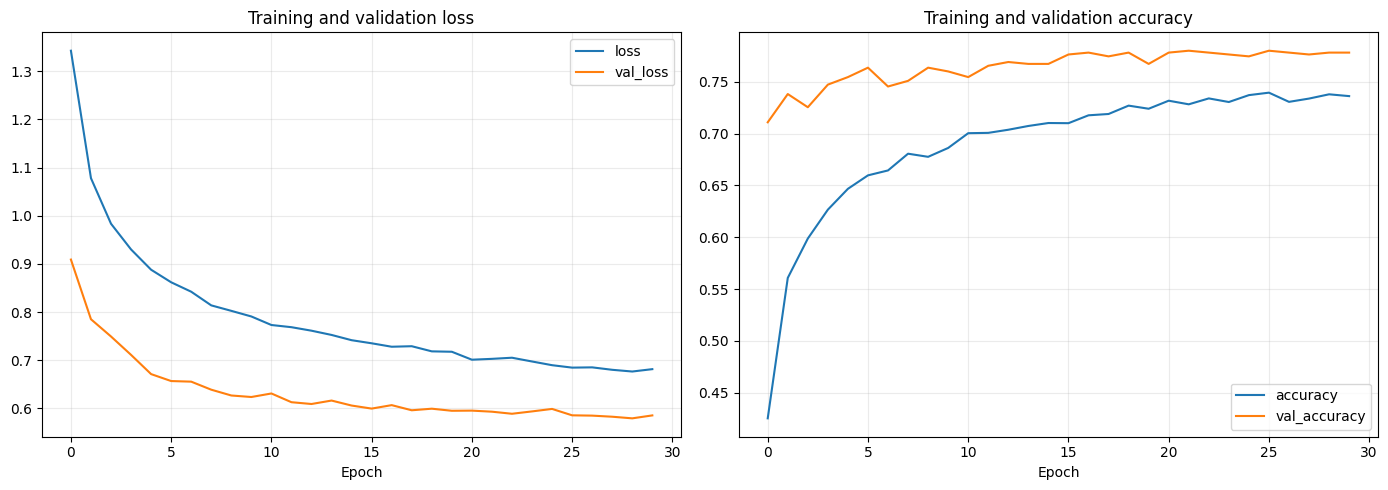

69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 173ms/step - accuracy: 0.7800 - loss: 0.5930
69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 171ms/step - accuracy: 0.7745 - loss: 0.6045
Best validation metrics: {'accuracy': 0.7799999713897705, 'loss': 0.5930492877960205}
Final test metrics: {'accuracy': 0.774545431137085, 'loss': 0.6045165061950684}
69/69 ━━━━━━━━━━━━━━━━━━━━ 15s 196ms/step
Accuracy: 0.7745
QWK: 0.8294
Macro F1: 0.5558


,precision,recall,f1-score,support
0 - No DR,0.949,0.963,0.956,271.000
1 - Mild,0.511,0.429,0.466,56.000
2 - Moderate,0.647,0.820,0.724,150.000
3 - Severe,0.462,0.207,0.286,29.000
4 - Proliferative,0.480,0.273,0.348,44.000
accuracy,0.775,0.775,0.775,0.775
macro avg,0.610,0.538,0.556,550.000
weighted avg,0.759,0.775,0.759,550.000


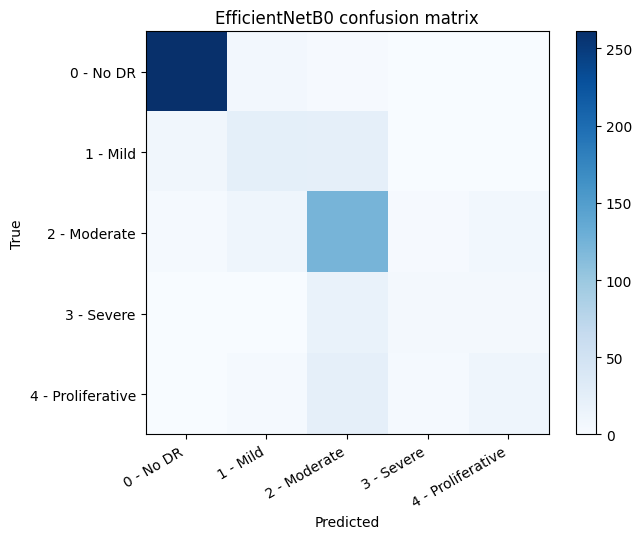

In [6]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=CLASS_WEIGHTS,
    callbacks=callbacks,
)

history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
history_df[['loss', 'val_loss']].plot(ax=axes[0], title='Training and validation loss')
history_df[['accuracy', 'val_accuracy']].plot(ax=axes[1], title='Training and validation accuracy')
for axis in axes:
    axis.set_xlabel('Epoch')
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

model.load_weights(CHECKPOINT_PATH)
validation_metrics = model.evaluate(val_ds, return_dict=True, verbose=1)
test_metrics = model.evaluate(test_ds, return_dict=True, verbose=1)
print('Best validation metrics:', validation_metrics)
print('Final test metrics:', test_metrics)

test_probabilities = model.predict(test_ds, verbose=1)
y_true = test_df['diagnosis'].to_numpy()
y_pred = test_probabilities.argmax(axis=1)
class_names = ['0 - No DR', '1 - Mild', '2 - Moderate', '3 - Severe', '4 - Proliferative']
print('Accuracy:', round(accuracy_score(y_true, y_pred), 4))
print('QWK:', round(cohen_kappa_score(y_true, y_pred, weights='quadratic'), 4))
print('Macro F1:', round(f1_score(y_true, y_pred, average='macro'), 4))
display(pd.DataFrame(classification_report(
    y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0,
)).T.round(3))
plt.figure(figsize=(7, 5.5))
plt.imshow(confusion_matrix(y_true, y_pred), cmap='Blues')
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=30, ha='right')
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('EfficientNetB0 confusion matrix')
plt.tight_layout()
plt.show()

69/69 ━━━━━━━━━━━━━━━━━━━━ 16s 194ms/step
Loaded model: D:\omar\SIC\grad_project\artefacts\EfficentNetB0\efficientnetb0_aptos_complete_model.keras
Test split: D:\omar\SIC\grad_project\datasets\aptos_512_clahe_balanced\test (550 images)
Classification report:
                   precision    recall  f1-score   support

        0 - No DR     0.9491    0.9631    0.9560       271
         1 - Mild     0.5106    0.4286    0.4660        56
     2 - Moderate     0.6474    0.8200    0.7235       150
       3 - Severe     0.4615    0.2069    0.2857        29
4 - Proliferative     0.4800    0.2727    0.3478        44

         accuracy                         0.7745       550
        macro avg     0.6097    0.5383    0.5558       550
     weighted avg     0.7589    0.7745    0.7587       550

Confusion matrix (rows = true, columns = predicted):
[[261   7   3   0   0]
 [  9  24  23   0   0]
 [  4  12 123   3   8]
 [  0   0  18   6   5]
 [  1   4  23   4  12]]


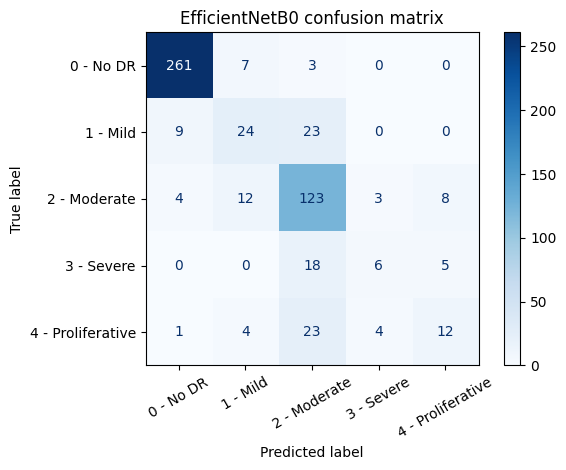

In [1]:
#Reload the saved EfficientNetB0 model and evaluate it on the held-out test split.
#we need classification report and confusion matrix not working
#added older settings are not changed (omar amur)
from pathlib import Path
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Find the saved model and balanced test split from either the project root or this notebook's parent.
model_candidates = [
    Path('artefacts/EfficentNetB0/efficientnetb0_aptos_complete_model.keras'),
    Path('../artefacts/EfficentNetB0/efficientnetb0_aptos_complete_model.keras'),
]
model_path = next((path.resolve() for path in model_candidates if path.is_file()), None)
if model_path is None:
    raise FileNotFoundError('Could not find the saved EfficientNetB0 model in artefacts/EfficentNetB0.')

split_candidates = [
    Path('datasets/aptos_512_clahe_balanced/test'),
    Path('Dataset/aptos_512_clahe_balanced/test'),
    Path('../datasets/aptos_512_clahe_balanced/test'),
    Path('../Dataset/aptos_512_clahe_balanced/test'),
]
test_root = next((path.resolve() for path in split_candidates if (path / 'labels.csv').is_file()), None)
if test_root is None:
    raise FileNotFoundError('Could not find the balanced test split with labels.csv.')

evaluation_model = tf.keras.models.load_model(model_path, compile=False)
test_labels = pd.read_csv(test_root / 'labels.csv')
required_columns = {'id_code', 'diagnosis'}
if not required_columns.issubset(test_labels.columns):
    raise ValueError(f'Test labels must contain columns: {sorted(required_columns)}')
test_labels['diagnosis'] = test_labels['diagnosis'].astype('int32')
test_labels['image_path'] = test_labels['id_code'].map(
    lambda image_id: str(test_root / 'images' / f'{image_id}.png')
)
missing_images = test_labels.loc[~test_labels['image_path'].map(os.path.isfile), 'image_path']
if not missing_images.empty:
    raise FileNotFoundError(f'Missing test images, for example: {missing_images.iloc[0]}')

# Match the notebook's original test preprocessing: PNG decode and resize to 224x224, no normalization.
image_size = tuple(evaluation_model.input_shape[1:3])
batch_size = 8

def _load_test_image(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, image_size, method='lanczos3')
    return tf.cast(image, tf.float32), label

test_dataset = tf.data.Dataset.from_tensor_slices((
    test_labels['image_path'].to_numpy(dtype=str),
    test_labels['diagnosis'].to_numpy(dtype=np.int32),
)).map(_load_test_image, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size).prefetch(tf.data.AUTOTUNE)

y_true = test_labels['diagnosis'].to_numpy(dtype=np.int32)
y_pred = evaluation_model.predict(test_dataset.map(lambda image, label: image), verbose=1).argmax(axis=1)
class_names = ['0 - No DR', '1 - Mild', '2 - Moderate', '3 - Severe', '4 - Proliferative']
labels = list(range(len(class_names)))

print(f'Loaded model: {model_path}')
print(f'Test split: {test_root} ({len(test_labels)} images)')
print('Classification report:')
print(classification_report(
    y_true, y_pred, labels=labels, target_names=class_names, digits=4, zero_division=0,
))

cm = confusion_matrix(y_true, y_pred, labels=labels)
print('Confusion matrix (rows = true, columns = predicted):')
print(cm)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    cmap='Blues', xticks_rotation=30, values_format='d'
)
plt.title('EfficientNetB0 confusion matrix')
plt.tight_layout()
plt.show()


69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 149ms/step
ROC curve saved to: D:\omar\SIC\grad_project\artefacts\EfficentNetB0\efficientnetb0_roc_curve.png


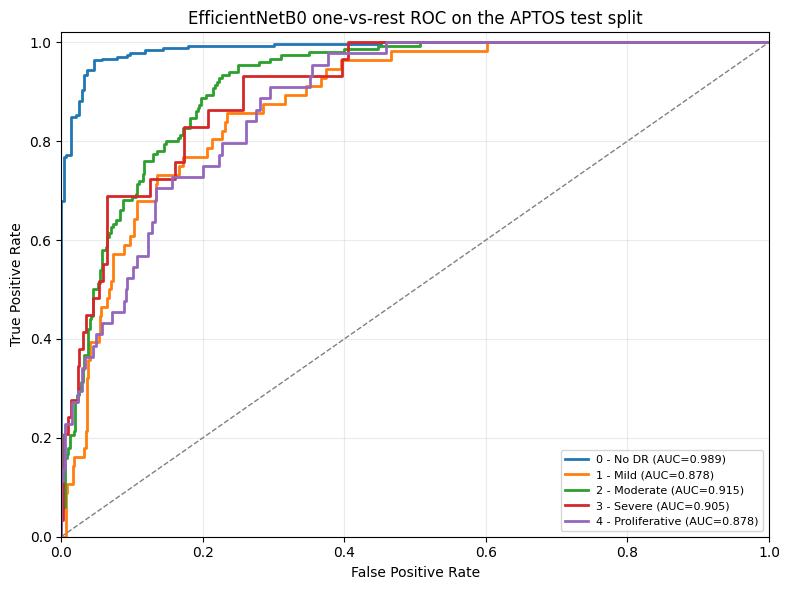

In [1]:
# Reload the saved EfficientNetB0 model and plot its one-vs-rest ROC curves.
from pathlib import Path
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

model_candidates = [
    Path('artefacts/EfficentNetB0/efficientnetb0_aptos_complete_model.keras'),
    Path('../artefacts/EfficentNetB0/efficientnetb0_aptos_complete_model.keras')
]
roc_model_path = next((p.resolve() for p in model_candidates if p.is_file()), None)
if roc_model_path is None:
    raise FileNotFoundError('Could not find the saved EfficientNetB0 model.')

test_split_candidates = [
    Path('datasets/aptos_512_clahe_balanced/test'),
    Path('Dataset/aptos_512_clahe_balanced/test'),
    Path('../datasets/aptos_512_clahe_balanced/test'),
    Path('../Dataset/aptos_512_clahe_balanced/test'),
]
roc_test_root = next((p.resolve() for p in test_split_candidates if (p / 'labels.csv').is_file()), None)
if roc_test_root is None:
    raise FileNotFoundError('Could not find the balanced test split with labels.csv.')
roc_frame = pd.read_csv(roc_test_root / 'labels.csv')
roc_y_true = roc_frame['diagnosis'].to_numpy(dtype=np.int32)
class_ids = np.arange(5)
roc_y_one_hot = label_binarize(roc_y_true, classes=class_ids)
class_names = ['0 - No DR', '1 - Mild', '2 - Moderate', '3 - Severe', '4 - Proliferative']

roc_model = tf.keras.models.load_model(roc_model_path, compile=False)
input_size = tuple(roc_model.input_shape[1:3])
image_paths = roc_frame['id_code'].map(
    lambda image_id: str(roc_test_root / 'images' / f'{image_id}.png')
).to_numpy(dtype=str)
missing = [p for p in image_paths if not os.path.isfile(p)]
if missing:
    raise FileNotFoundError(f'Missing test image: {missing[0]}')

def _decode_roc_image(path):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, input_size, method='lanczos3')
    image = tf.cast(image, tf.float32)
    return image

roc_test_ds = (tf.data.Dataset.from_tensor_slices(image_paths)
               .map(_decode_roc_image, num_parallel_calls=tf.data.AUTOTUNE)
               .batch(8).prefetch(tf.data.AUTOTUNE))
roc_scores = roc_model.predict(roc_test_ds, verbose=1)

fig, ax = plt.subplots(figsize=(8, 6))
for class_index, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(roc_y_one_hot[:, class_index], roc_scores[:, class_index])
    class_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=2, label=f'{class_name} (AUC={class_auc:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='False Positive Rate', ylabel='True Positive Rate',
       title='EfficientNetB0 one-vs-rest ROC on the APTOS test split')
ax.grid(alpha=0.25)
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
roc_output_path = roc_model_path.parent / 'efficientnetb0_roc_curve.png'
fig.savefig(roc_output_path, dpi=200, bbox_inches='tight')
print(f'ROC curve saved to: {roc_output_path}')
plt.show()
